# EDA: NYC 311 Street Condition Requests (2025)

Target: `closed_48h` (1 = closed within 48 hours, 0 = not).

In [1]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt

df = pd.read_csv('../data/street_conditions_2025_labeled.csv', low_memory=False)
print(df.shape)
print(df.dtypes)

(70322, 38)
unique_key                          int64
created_date                          str
closed_date                           str
agency                                str
agency_name                           str
complaint_type                        str
descriptor                            str
incident_zip                      float64
intersection_street_1                 str
intersection_street_2                 str
address_type                          str
city                                  str
facility_type                     float64
status                                str
resolution_description                str
resolution_action_updated_date        str
community_board                       str
council_district                  float64
police_precinct                       str
borough                               str
x_coordinate_state_plane          float64
y_coordinate_state_plane          float64
open_data_channel_type                str
park_facility_name    

In [2]:
# convert dates and create new features from the filing time
df['created_date'] = pd.to_datetime(df['created_date'])
df['closed_date'] = pd.to_datetime(df['closed_date'])

df['hour'] = df['created_date'].dt.hour
df['month'] = df['created_date'].dt.month
df['day_of_week'] = df['created_date'].dt.day_name()

df['borough'] = df['borough'].replace('Unspecified', np.nan)
df['location_missing'] = df['latitude'].isna()

print(df[['created_date', 'hour', 'month', 'day_of_week']].head())

         created_date  hour  month day_of_week
0 2025-04-01 00:25:10     0      4     Tuesday
1 2025-04-01 01:24:08     1      4     Tuesday
2 2025-04-01 02:41:23     2      4     Tuesday
3 2025-04-01 02:43:21     2      4     Tuesday
4 2025-04-01 04:28:55     4      4     Tuesday


## 1. Data quality

In [3]:
# missing values
print(df[['closed_date', 'descriptor', 'borough', 'incident_zip', 'latitude', 'longitude',
          'address_type', 'open_data_channel_type']].isna().sum())

# duplicates
print('duplicate IDs:', df['unique_key'].duplicated().sum())

closed_date                3475
descriptor                    0
borough                     132
incident_zip                749
latitude                  19601
longitude                 19601
address_type                  0
open_data_channel_type        0
dtype: int64
duplicate IDs: 0


In [4]:
# missing location by address type
count_matrix = df.groupby(['address_type', 'location_missing']).size().unstack()
print(count_matrix)

location_missing    False    True 
address_type                      
ADDRESS           27739.0      9.0
BLOCKFACE           163.0  19476.0
INTERSECTION      22663.0    116.0
PLACE                72.0      NaN
PLACENAME            26.0      NaN
UNRECOGNIZED         58.0      NaN


In [5]:
# closure time of 0 hours
print('closure time = 0 hours:', (df['closure_hours'] == 0).sum())
print(df[df['closure_hours'] == 0]['open_data_channel_type'].value_counts())

closure time = 0 hours: 3276
open_data_channel_type
UNKNOWN    3276
Name: count, dtype: int64


## 2. Target variable

closed_48h
1    44355
0    25967
Name: count, dtype: int64
closed_48h
1    0.630741
0    0.369259
Name: proportion, dtype: float64


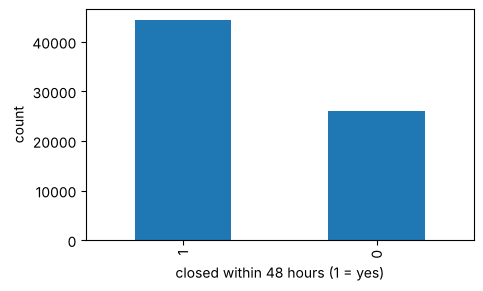

In [6]:
print(df['closed_48h'].value_counts())
print(df['closed_48h'].value_counts(normalize=True))

plt.figure(figsize=(5,3))
df['closed_48h'].value_counts().plot.bar()
plt.xlabel('closed within 48 hours (1 = yes)')
plt.ylabel('count')
plt.show()

count    66847.000000
mean        69.127957
std        230.147526
min          0.000000
25%         17.518194
50%         26.006389
75%         69.034722
max      12122.434444
Name: closure_hours, dtype: float64


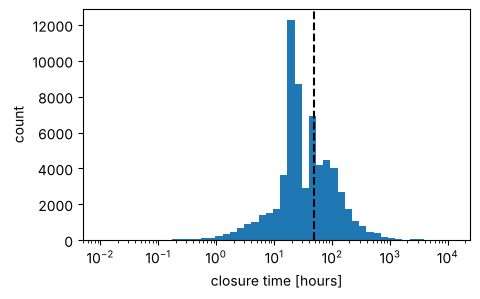

In [7]:
print(df['closure_hours'].describe())

# closure hours are very skewed, so use log bins and a log x-axis
plt.figure(figsize=(5,3))
df[df['closure_hours'] > 0]['closure_hours'].plot.hist(bins=np.logspace(np.log10(0.01), np.log10(df['closure_hours'].max()), 50))
plt.axvline(48, color='k', linestyle='--')
plt.semilogx()
plt.xlabel('closure time [hours]')
plt.ylabel('count')
plt.show()

## 3. Single features

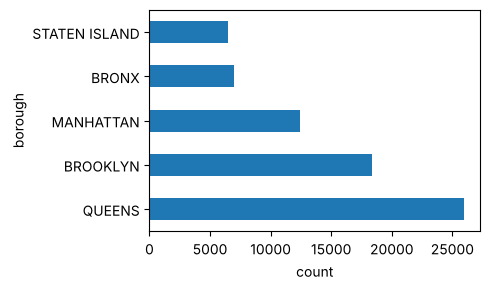

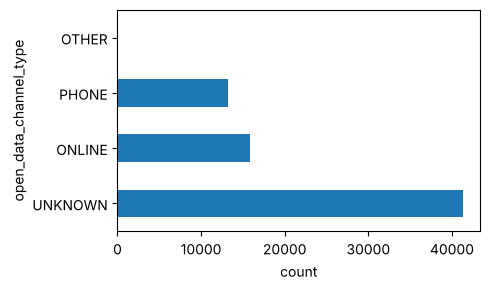

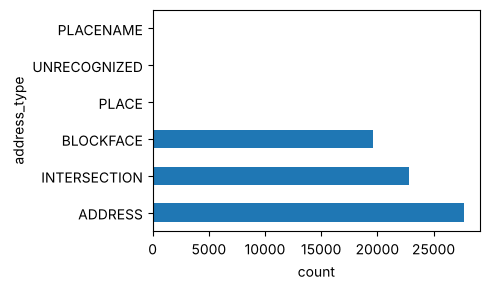

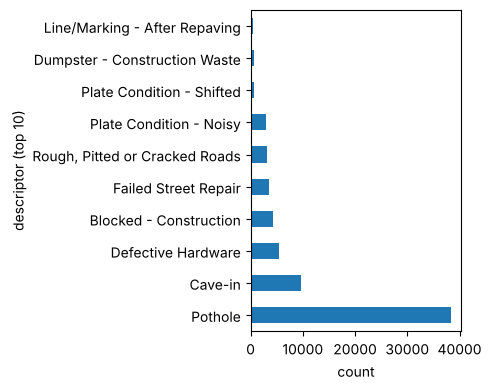

descriptor
Pothole                           38430
Cave-in                            9647
Defective Hardware                 5490
Blocked - Construction             4245
Failed Street Repair               3487
Rough, Pitted or Cracked Roads     3121
Plate Condition - Noisy            2927
Plate Condition - Shifted           622
Dumpster - Construction Waste       584
Line/Marking - After Repaving       507
Line/Marking - Faded                386
Wear & Tear                         291
Crash Cushion Defect                225
Guard Rail - Street                 106
Unsafe Worksite                      66
Plate Condition - Open               65
Plate Condition - Anti-Skid          53
Depression Maintenance               31
Defacement                           20
Hummock                              18
Strip Paving                          1
Name: count, dtype: int64


In [8]:
# categorical features
for col in ['borough', 'open_data_channel_type', 'address_type']:
    plt.figure(figsize=(5,3))
    df[col].value_counts().plot.barh()
    plt.xlabel('count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5,4))
df['descriptor'].value_counts().head(10).plot.barh()
plt.xlabel('count')
plt.ylabel('descriptor (top 10)')
plt.tight_layout()
plt.show()

print(df['descriptor'].value_counts())

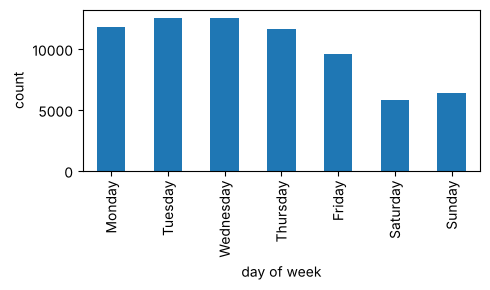

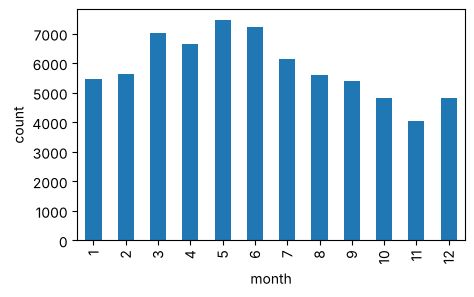

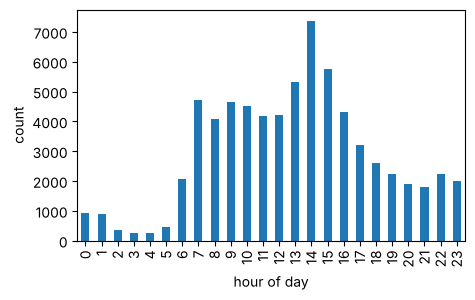

In [9]:
# ordinal features: keep the correct order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(5,3))
df['day_of_week'].value_counts().reindex(day_order).plot.bar()
plt.ylabel('count')
plt.xlabel('day of week')
plt.tight_layout()
plt.show()

plt.figure(figsize=(5,3))
df['month'].value_counts().sort_index().plot.bar()
plt.ylabel('count')
plt.xlabel('month')
plt.show()

plt.figure(figsize=(5,3))
df['hour'].value_counts().sort_index().plot.bar()
plt.ylabel('count')
plt.xlabel('hour of day')
plt.show()

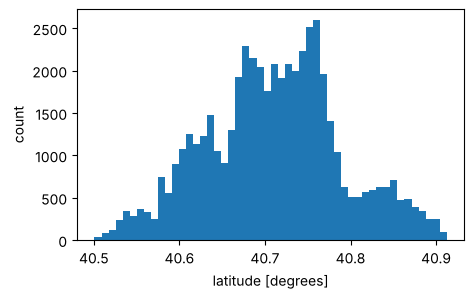

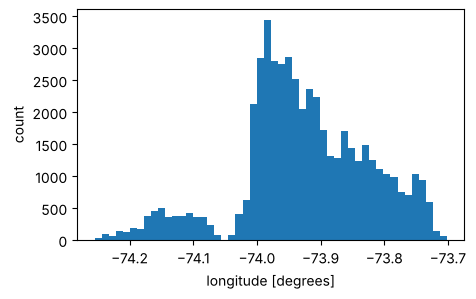

In [10]:
# continuous features
for col in ['latitude', 'longitude']:
    plt.figure(figsize=(5,3))
    df[col].plot.hist(bins=50)
    plt.xlabel(col + ' [degrees]')
    plt.ylabel('count')
    plt.show()

## 4. Features vs. target

closed_48h            0         1
borough                          
BRONX          0.610496  0.389504
BROOKLYN       0.386939  0.613061
MANHATTAN      0.285322  0.714678
QUEENS         0.354927  0.645073
STATEN ISLAND  0.277949  0.722051


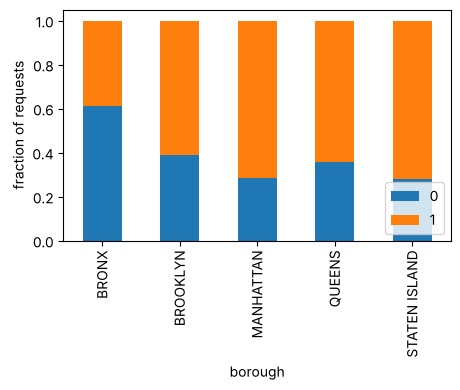

closed_48h                     0         1
open_data_channel_type                    
ONLINE                  0.493625  0.506375
OTHER                        NaN  1.000000
PHONE                   0.518081  0.481919
UNKNOWN                 0.274002  0.725998


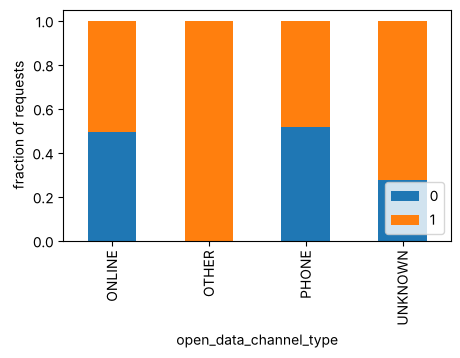

closed_48h           0         1
address_type                    
ADDRESS       0.412895  0.587105
BLOCKFACE     0.338612  0.661388
INTERSECTION  0.341191  0.658809
PLACE         0.652778  0.347222
PLACENAME     0.230769  0.769231
UNRECOGNIZED  0.603448  0.396552


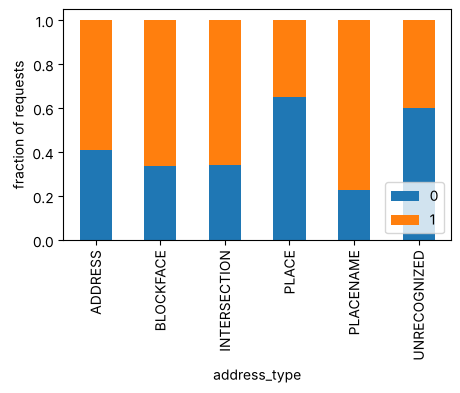

closed_48h         0         1
month                         
1           0.223420  0.776580
2           0.271967  0.728033
3           0.308447  0.691553
4           0.349001  0.650999
5           0.409854  0.590146
6           0.378210  0.621790
7           0.452664  0.547336
8           0.447943  0.552057
9           0.392534  0.607466
10          0.408159  0.591841
11          0.443072  0.556928
12          0.364333  0.635667


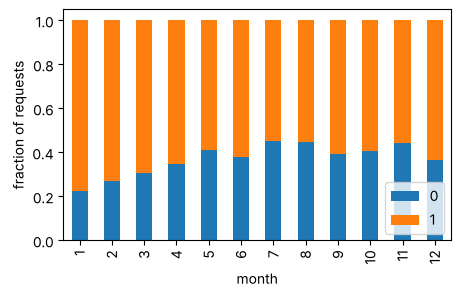

closed_48h         0         1
hour                          
0           0.320652  0.679348
1           0.254967  0.745033
2           0.299419  0.700581
3           0.367041  0.632959
4           0.428571  0.571429
5           0.291577  0.708423
6           0.352311  0.647689
7           0.339077  0.660923
8           0.427622  0.572378
9           0.446900  0.553100
10          0.452855  0.547145
11          0.461244  0.538756
12          0.432432  0.567568
13          0.329076  0.670924
14          0.272986  0.727014
15          0.342480  0.657520
16          0.372353  0.627647
17          0.399875  0.600125
18          0.408257  0.591743
19          0.400534  0.599466
20          0.411303  0.588697
21          0.386756  0.613244
22          0.252557  0.747443
23          0.213107  0.786893


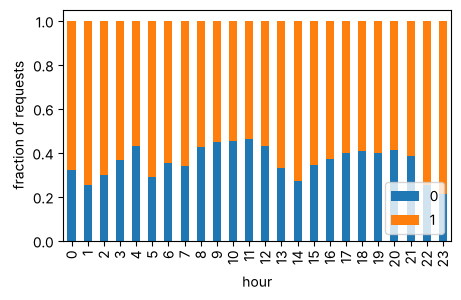

In [11]:
# categorical vs. target: stacked bar plots
for col in ['borough', 'open_data_channel_type', 'address_type', 'month', 'hour']:
    count_matrix = df.groupby([col, 'closed_48h']).size().unstack()
    count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
    print(count_matrix_norm)

    count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
    plt.ylabel('fraction of requests')
    plt.legend(loc=4)
    plt.show()

closed_48h          0         1
day_of_week                    
Monday       0.267170  0.732830
Tuesday      0.259805  0.740195
Wednesday    0.273827  0.726173
Thursday     0.334165  0.665835
Friday       0.708329  0.291671
Saturday     0.588883  0.411117
Sunday       0.316799  0.683201


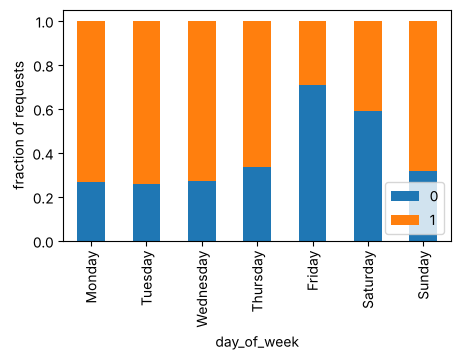

closed_date
Monday       12998
Tuesday      14007
Wednesday    13709
Thursday     11783
Friday       11825
Saturday      1354
Sunday        1171
Name: count, dtype: int64


In [12]:
# day of week vs. target (in the correct order)
count_matrix = df.groupby(['day_of_week', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0).reindex(day_order)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

# on which day are requests closed?
print(df['closed_date'].dt.day_name().value_counts().reindex(day_order))

closed_48h                             0         1
descriptor                                        
Blocked - Construction          0.507892  0.492108
Cave-in                         0.557168  0.442832
Defective Hardware              0.458652  0.541348
Dumpster - Construction Waste   0.525685  0.474315
Failed Street Repair            0.570691  0.429309
Line/Marking - After Repaving   1.000000       NaN
Plate Condition - Noisy         0.327639  0.672361
Plate Condition - Shifted       0.360129  0.639871
Pothole                         0.254723  0.745277
Rough, Pitted or Cracked Roads  0.340916  0.659084


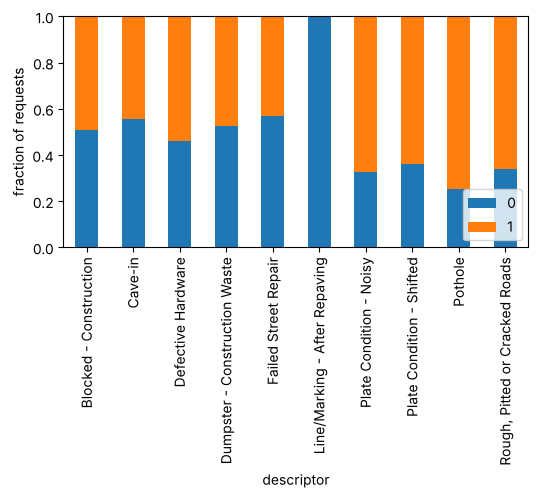

In [13]:
# descriptor vs. target (top 10)
top10 = df['descriptor'].value_counts().head(10).index
count_matrix = df[df['descriptor'].isin(top10)].groupby(['descriptor', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(6,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

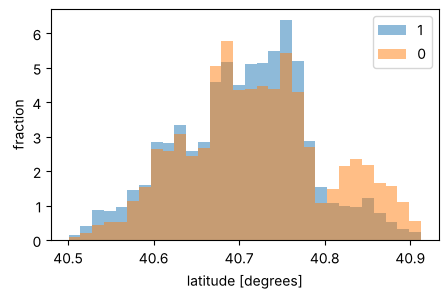

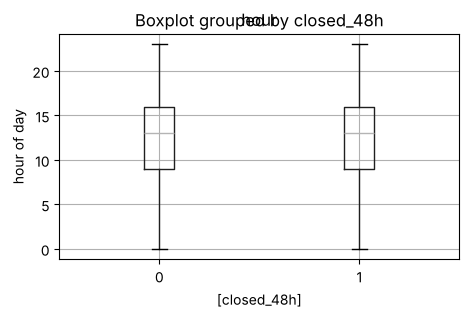

In [14]:
# continuous vs. target: category-specific histograms
categories = df['closed_48h'].unique()
bin_range = (df['latitude'].min(), df['latitude'].max())

plt.figure(figsize=(5,3))
for c in categories:
    plt.hist(df[df['closed_48h'] == c]['latitude'], alpha=0.5, label=c, range=bin_range, bins=30, density=True)
plt.legend()
plt.ylabel('fraction')
plt.xlabel('latitude [degrees]')
plt.show()

# box plot
df[['hour', 'closed_48h']].boxplot(by='closed_48h', figsize=(5,3))
plt.ylabel('hour of day')
plt.show()

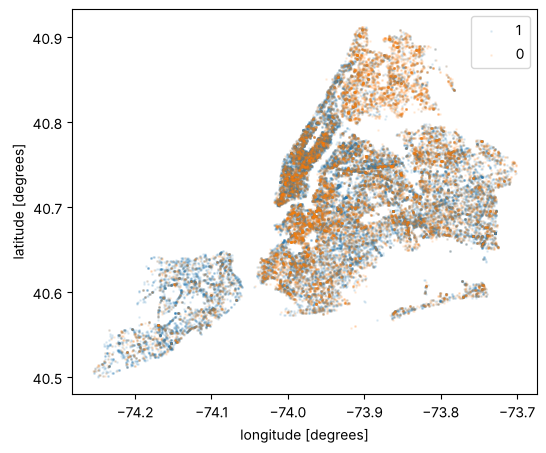

In [15]:
# location: scatter plot, one color per class
plt.figure(figsize=(6,5))
for c in categories:
    plt.scatter(df[df['closed_48h'] == c]['longitude'], df[df['closed_48h'] == c]['latitude'],
                s=1, alpha=0.1, label=c)
plt.legend()
plt.xlabel('longitude [degrees]')
plt.ylabel('latitude [degrees]')
plt.show()

## 5. Time structure

month
1     0.776580
2     0.728033
3     0.691553
4     0.650999
5     0.590146
6     0.621790
7     0.547336
8     0.552057
9     0.607466
10    0.591841
11    0.556928
12    0.635667
Name: closed_48h, dtype: float64


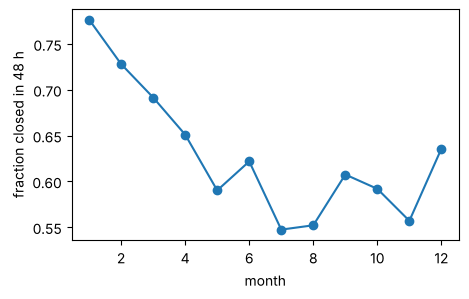

In [16]:
# monthly share closed within 48 hours
print(df.groupby('month')['closed_48h'].mean())

plt.figure(figsize=(5,3))
df.groupby('month')['closed_48h'].mean().plot(marker='o')
plt.xlabel('month')
plt.ylabel('fraction closed in 48 h')
plt.show()

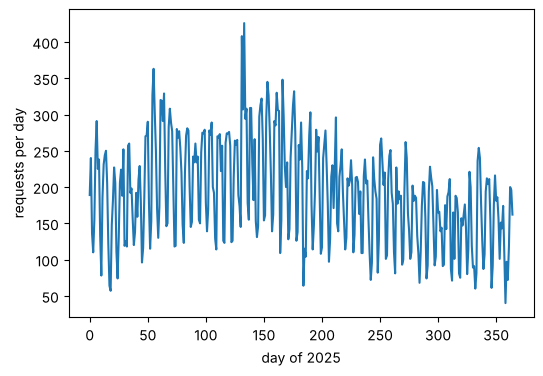

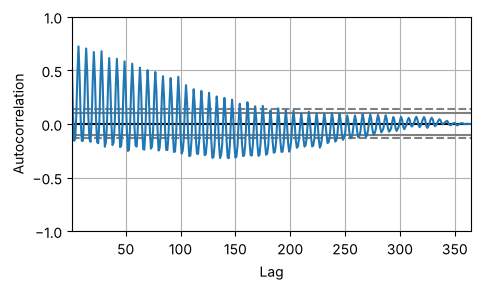

In [17]:
# number of requests per day
daily = df.groupby(df['created_date'].dt.date).size()

plt.figure(figsize=(6,4))
plt.plot(daily.values)
plt.xlabel('day of 2025')
plt.ylabel('requests per day')
plt.show()

# autocorrelation
plt.figure(figsize=(5,3))
pd.plotting.autocorrelation_plot(daily)
plt.tight_layout()
plt.show()

## 6. Figures for the report

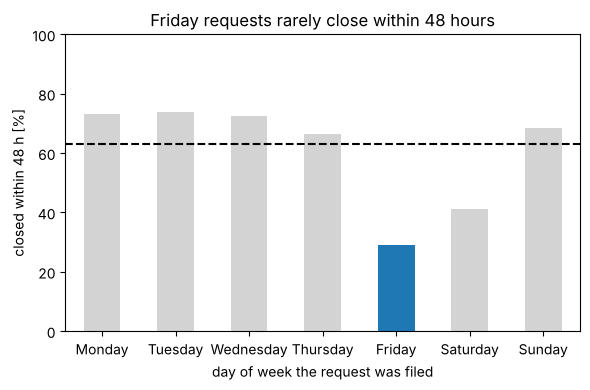

In [18]:
# Figure 1: day of week
by_day = df.groupby('day_of_week')['closed_48h'].mean().reindex(day_order) * 100
colors = ['tab:blue' if d == 'Friday' else 'lightgray' for d in day_order]

plt.figure(figsize=(6,4))
by_day.plot.bar(color=colors)
plt.axhline(df['closed_48h'].mean() * 100, color='k', linestyle='--')   # all days
plt.title('Friday requests rarely close within 48 hours')
plt.xlabel('day of week the request was filed')
plt.ylabel('closed within 48 h [%]')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig('../figures/fig1_day_of_week.png', dpi=200)
plt.show()

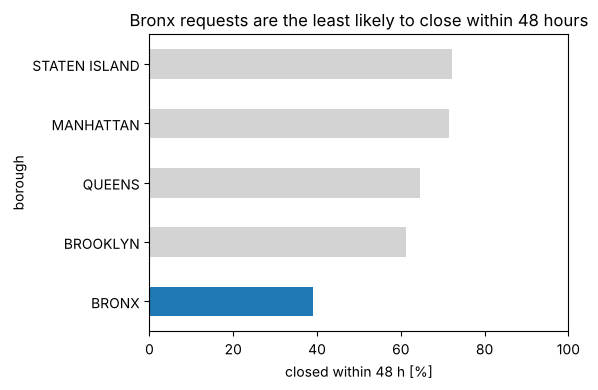

In [19]:
# Figure 2: borough
by_borough = df.groupby('borough')['closed_48h'].mean().sort_values() * 100
colors = ['tab:blue' if b == 'BRONX' else 'lightgray' for b in by_borough.index]

plt.figure(figsize=(6,4))
by_borough.plot.barh(color=colors)
plt.title('Bronx requests are the least likely to close within 48 hours')
plt.xlabel('closed within 48 h [%]')
plt.ylabel('borough')
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig('../figures/fig2_borough.png', dpi=200)
plt.show()

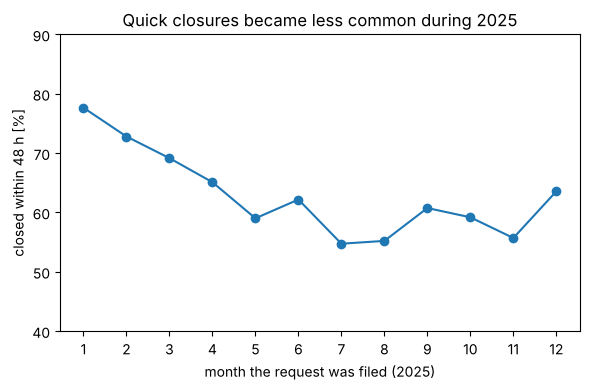

In [20]:
# Figure 3: month
by_month = df.groupby('month')['closed_48h'].mean() * 100

plt.figure(figsize=(6,4))
plt.plot(by_month.index, by_month.values, marker='o')
plt.title('Quick closures became less common during 2025')
plt.xlabel('month the request was filed (2025)')
plt.ylabel('closed within 48 h [%]')
plt.xticks(range(1, 13))
plt.ylim(40, 90)
plt.tight_layout()
plt.savefig('../figures/fig3_month.png', dpi=200)
plt.show()